# Uczenie maszynowe 1
## Pracownia specjalistyczna nr 5
### Redukcja wymiarowości: PCA, t-SNE i UMAP

## Cele zajęć

Po wykonaniu ćwiczeń student powinien potrafić:

- wyjaśnić, czym różni się selekcja cech od ekstrakcji cech,
- przeprowadzić PCA krok po kroku,
- interpretować wartości własne i udział wyjaśnianej wariancji,
- wybrać liczbę składowych głównych,
- uzyskać zbiór z mniejszą liczbą zmiennych niż zbiór wejściowy,
- interpretować ładunki składowych,
- wyjaśnić wpływ parametru `perplexity` na wynik t-SNE.

# 1. Import bibliotek


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 2. PCA krok po kroku – mały przykład

Zaczniemy od niewielkiego zbioru zawierającego wyniki sześciu osób z dwóch testów.

Dla tak małych danych możemy zobaczyć wszystkie etapy PCA:

1. standaryzację,
2. macierz kowariancji,
3. wartości własne i wektory własne,
4. udział wyjaśnianej wariancji,
5. rzutowanie danych na nowe osie.


In [3]:
X_small = pd.DataFrame({
    "Test1": [10, 11, 8, 3, 1, 2],
    "Test2": [6, 4, 5, 3, 2.8, 1]
})

X_small

,Test1,Test2
0,10,6.0
1,11,4.0
2,8,5.0
3,3,3.0
4,1,2.8
5,2,1.0


## 2.1. Standaryzacja

Ponieważ obie cechy mogą mieć różne zakresy i wariancje, najpierw je standaryzujemy.

`StandardScaler` wykorzystuje odchylenie standardowe obliczane z dzielnikiem `N`, dlatego po standaryzacji każda kolumna ma:

- średnią około `0`,
- wariancję około `1` przy dzielniku `N`.


In [4]:
scaler_small = StandardScaler()

Z = scaler_small.fit_transform(X_small)

Z_df = pd.DataFrame(
    Z,
    columns=["z1", "z2"]
)

Z_df.round(4)

,z1,z2
0,1.0481,1.4662
1,1.2996,0.2272
2,0.5450,0.8467
3,-0.7127,-0.3924
4,-1.2157,-0.5163
5,-0.9642,-1.6314


In [5]:
print("Średnie:")
print(np.mean(Z, axis=0))

print("\nWariancje z dzielnikiem N:")
print(np.var(Z, axis=0, ddof=0))

Średnie:
[5.55111512e-17 7.40148683e-17]

Wariancje z dzielnikiem N:
[1. 1.]


## 2.2. Metoda 1 – macierz kowariancji i rozkład własny

Macierz kowariancji opisuje wariancje cech oraz ich współzmienność.

Ponieważ wcześniej użyliśmy `StandardScaler`, a teraz `np.cov(..., ddof=1)`, wartości na przekątnej będą większe od 1.  
Dla 6 obserwacji otrzymujemy czynnik `6/5 = 1.2`.


In [6]:
C = np.cov(
    Z,
    rowvar=False,
    ddof=1
)

print("Macierz kowariancji C:")
print(np.round(C, 4))

Macierz kowariancji C:
[[1.2    0.9547]
 [0.9547 1.2   ]]


Teraz obliczamy wartości własne i wektory własne macierzy kowariancji.

`np.linalg.eigh()` jest odpowiednia dla macierzy symetrycznych, takich jak macierz kowariancji.


In [7]:
eigenvalues, eigenvectors = np.linalg.eigh(C)

order = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

print("Wartości własne:")
print(np.round(eigenvalues, 4))

print("\nWektory własne - kolumny:")
print(np.round(eigenvectors, 4))

Wartości własne:
[2.1547 0.2453]

Wektory własne - kolumny:
[[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]


### Udział wyjaśnianej wariancji

Wartość własna odpowiada wariancji danych w kierunku danej składowej.

Udział wariancji składowej:

$$
EVR_k = \frac{\lambda_k}{\sum_j \lambda_j}
$$


In [8]:
explained_ratio_eig = (
    eigenvalues / eigenvalues.sum()
)

for i, value in enumerate(explained_ratio_eig, start=1):
    print(
        f"PC{i}: {value*100:.2f}% wariancji"
    )

PC1: 89.78% wariancji
PC2: 10.22% wariancji


## 2.3. Transformacja danych

Macierz `W` zawiera wybrane wektory własne.

Dane w przestrzeni PCA otrzymujemy przez:

$$
T = ZW
$$


In [9]:
W = eigenvectors

T_eig = Z @ W

T_eig_df = pd.DataFrame(
    T_eig,
    columns=["PC1", "PC2"]
)

T_eig_df.round(4)

,PC1,PC2
0,1.7778,0.2957
1,1.0796,-0.7583
2,0.9840,0.2133
3,-0.7814,0.2265
4,-1.2247,0.4946
5,-1.8354,-0.4718


## 2.4. Jak wyglądają nowe osie?

Na wykresie pokazujemy standaryzowane obserwacje oraz kierunki PC1 i PC2.


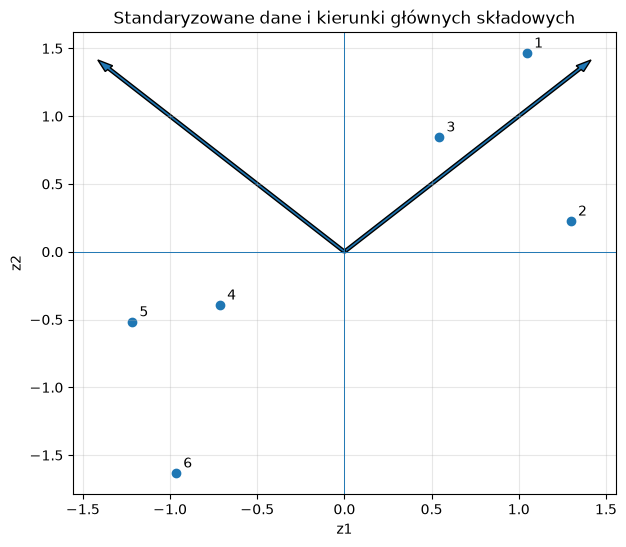

In [10]:
plt.figure(figsize=(7, 6))

plt.scatter(
    Z[:, 0],
    Z[:, 1]
)

for i in range(len(Z)):
    plt.text(
        Z[i, 0] + 0.04,
        Z[i, 1] + 0.04,
        str(i + 1)
    )

scale_arrow = 2.0

plt.arrow(
    0, 0,
    eigenvectors[0, 0] * scale_arrow,
    eigenvectors[1, 0] * scale_arrow,
    width=0.02,
    length_includes_head=True
)

plt.arrow(
    0, 0,
    eigenvectors[0, 1] * scale_arrow,
    eigenvectors[1, 1] * scale_arrow,
    width=0.02,
    length_includes_head=True
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Standaryzowane dane i kierunki głównych składowych")
plt.axhline(0, linewidth=0.7)
plt.axvline(0, linewidth=0.7)
plt.grid(alpha=0.3)
plt.show()

# 3. Ta sama PCA przez SVD

Dla macierzy standaryzowanych / wycentrowanych danych:

$$
Z = U\Sigma V^T
$$

kolumny macierzy `V` są kierunkami głównych składowych.

Związek wartości osobliwych z wartościami własnymi macierzy kowariancji:

$$
\lambda_k = \frac{\sigma_k^2}{N-1}
$$

Pokażemy teraz, że otrzymujemy te same kierunki i te same współrzędne obserwacji, z dokładnością do możliwej zmiany znaku całej osi.


In [11]:
U, S, Vt = np.linalg.svd(
    Z,
    full_matrices=False
)

V = Vt.T

eigenvalues_svd = (
    S**2 / (Z.shape[0] - 1)
)

print("Wartości własne z metody 1:")
print(np.round(eigenvalues, 6))

print("\nWartości własne otrzymane z SVD:")
print(np.round(eigenvalues_svd, 6))

Wartości własne z metody 1:
[2.154705 0.245295]

Wartości własne otrzymane z SVD:
[2.154705 0.245295]


## 3.1. Porównanie kierunków

Wektor własny można pomnożyć przez `-1` i nadal opisuje tę samą oś.

Dlatego przy porównywaniu PCA i SVD musimy dopuścić zmianę znaku.


In [12]:
print("Wektory własne z macierzy kowariancji:")
print(np.round(eigenvectors, 4))

print("\nPrawe wektory osobliwe z SVD:")
print(np.round(V, 4))

print(
    "\nCzy wartości bezwzględne kierunków są takie same?",
    np.allclose(
        np.abs(eigenvectors),
        np.abs(V)
    )
)

Wektory własne z macierzy kowariancji:
[[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]

Prawe wektory osobliwe z SVD:
[[-0.7071 -0.7071]
 [-0.7071  0.7071]]

Czy wartości bezwzględne kierunków są takie same? True


## 3.2. Porównanie współrzędnych obserwacji

Z SVD współrzędne obserwacji w nowej przestrzeni możemy otrzymać jako:

$$
T = U\Sigma
$$

Dopasujemy jedynie znak osi, aby łatwo porównać wynik z metodą opartą na macierzy kowariancji.


In [13]:
signs = np.sign(
    np.sum(
        eigenvectors * V,
        axis=0
    )
)

signs[signs == 0] = 1

T_svd = (
    U * S
) * signs

print("Pierwsze współrzędne - metoda własna:")
print(np.round(T_eig, 4))

print("\nPierwsze współrzędne - SVD:")
print(np.round(T_svd, 4))

print(
    "\nCzy wyniki są równoważne?",
    np.allclose(T_eig, T_svd)
)

Pierwsze współrzędne - metoda własna:
[[ 1.7778  0.2957]
 [ 1.0796 -0.7583]
 [ 0.984   0.2133]
 [-0.7814  0.2265]
 [-1.2247  0.4946]
 [-1.8354 -0.4718]]

Pierwsze współrzędne - SVD:
[[ 1.7778  0.2957]
 [ 1.0796 -0.7583]
 [ 0.984   0.2133]
 [-0.7814  0.2265]
 [-1.2247  0.4946]
 [-1.8354 -0.4718]]

Czy wyniki są równoważne? True


### Najważniejszy wniosek

Dla danych wycentrowanych PCA obliczona przez:

- rozkład własny macierzy kowariancji,
- SVD macierzy danych

prowadzi do tych samych głównych kierunków i tej samej reprezentacji danych, z możliwością odwrócenia znaku całej osi.


# 4. PCA ze scikit-learn

W praktyce nie liczymy ręcznie wartości własnych.

`sklearn.decomposition.PCA` wykorzystuje numerycznie stabilne metody oparte m.in. na SVD.


In [14]:
pca_small = PCA(n_components=2)

T_sklearn = pca_small.fit_transform(Z)

print("Udział wyjaśnianej wariancji:")
print(
    np.round(
        pca_small.explained_variance_ratio_,
        4
    )
)

print("\nWspółczynniki głównych składowych:")
print(
    np.round(
        pca_small.components_,
        4
    )
)

Udział wyjaśnianej wariancji:
[0.8978 0.1022]

Współczynniki głównych składowych:
[[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]


# 5. Własny zbiór danych – 8 cech wejściowych

Teraz przejdziemy do większego zbioru.

Każda obserwacja opisuje studenta za pomocą 8 cech numerycznych:

- `matematyka`,
- `statystyka`,
- `programowanie`,
- `algorytmy`,
- `projekt`,
- `komunikacja`,
- `czas_nauki_h`,
- `aktywnosc_pct`.

Kolumna `profil` jest etykietą używaną wyłącznie do wizualizacji.  
PCA **nie korzysta z etykiet klas podczas wyznaczania składowych**.


In [15]:
df = pd.read_csv(
    "redukcja_wymiarow_pracownia5.csv"
)

print("Rozmiar danych:", df.shape)
df.head()

Rozmiar danych: (270, 10)


,id,profil,matematyka,statystyka,programowanie,algorytmy,projekt,komunikacja,czas_nauki_h,aktywnosc_pct
0,1,analityczny,33.4,41.7,47.7,40.6,79.8,77.9,1.0,70.8
1,2,analityczny,56.2,51.7,63.0,57.7,81.7,72.8,8.5,72.5
2,3,analityczny,52.8,48.5,56.2,60.5,77.5,71.3,8.1,59.9
3,4,analityczny,57.3,56.0,66.4,60.2,87.3,76.7,8.9,69.4
4,5,analityczny,53.8,55.1,68.8,68.0,79.8,69.7,10.1,53.7


In [16]:
features = [
    "matematyka",
    "statystyka",
    "programowanie",
    "algorytmy",
    "projekt",
    "komunikacja",
    "czas_nauki_h",
    "aktywnosc_pct"
]

X = df[features]

print("Liczba oryginalnych cech:", X.shape[1])

Liczba oryginalnych cech: 8


## 5.1. Dlaczego standaryzujemy dane?

PCA opiera się na wariancji.  
Jeżeli jedna cecha ma dużo większą skalę niż pozostałe, może zdominować wynik.

Dlatego dla cech mierzonych w różnych jednostkach stosujemy standaryzację.


In [17]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

X_scaled_df.head()

,matematyka,statystyka,programowanie,algorytmy,projekt,komunikacja,czas_nauki_h,aktywnosc_pct
0,-2.210604,-1.655283,-1.559368,-2.014557,1.137225,1.375312,-2.125921,1.081302
1,-0.838533,-1.021426,-0.337929,-0.654771,1.397798,0.725837,-0.715189,1.269437
2,-1.043140,-1.224260,-0.880791,-0.432116,0.821795,0.534815,-0.790428,-0.124972
3,-0.772336,-0.748867,-0.066498,-0.455972,2.165802,1.222494,-0.639950,0.926368
4,-0.982961,-0.805914,0.125101,0.164282,1.137225,0.331058,-0.414233,-0.811110


# 6. Ile składowych głównych zachować?

Najpierw wykonamy PCA bez ograniczania liczby składowych.


In [18]:
pca_all = PCA()

X_pca_all = pca_all.fit_transform(
    X_scaled
)

explained = (
    pca_all.explained_variance_ratio_
)

cumulative = np.cumsum(explained)

variance_table = pd.DataFrame({
    "skladowa": [
        f"PC{i}"
        for i in range(1, len(explained) + 1)
    ],
    "wariancja_wyjasniona": explained,
    "wariancja_skumulowana": cumulative
})

variance_table

,skladowa,wariancja_wyjasniona,wariancja_skumulowana
0,PC1,0.561401,0.561401
1,PC2,0.243410,0.804810
2,PC3,0.141010,0.945820
3,PC4,0.021436,0.967255
4,PC5,0.016162,0.983418
5,PC6,0.007240,0.990658
6,PC7,0.005430,0.996088
7,PC8,0.003912,1.000000


## 6.1. Wykres udziału wariancji

Pierwsze składowe powinny wyjaśniać największą część zmienności danych.


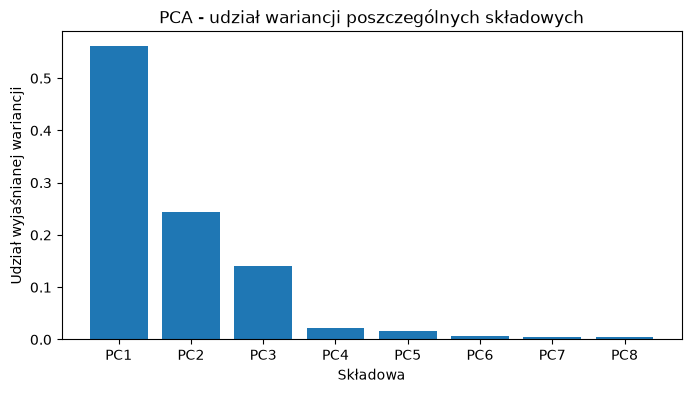

In [19]:
plt.figure(figsize=(8, 4))

plt.bar(
    variance_table["skladowa"],
    variance_table["wariancja_wyjasniona"]
)

plt.xlabel("Składowa")
plt.ylabel("Udział wyjaśnianej wariancji")
plt.title("PCA - udział wariancji poszczególnych składowych")
plt.show()

## 6.2. Wariancja skumulowana

Ten wykres pomaga zdecydować, ile składowych potrzeba, aby zachować np. 90% lub 95% wariancji.


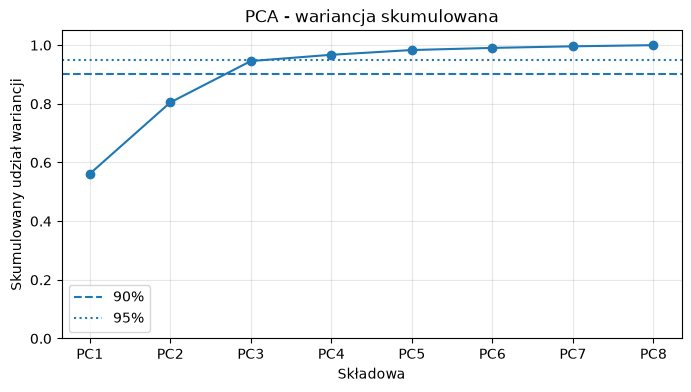

In [20]:
plt.figure(figsize=(8, 4))

plt.plot(
    variance_table["skladowa"],
    variance_table["wariancja_skumulowana"],
    marker="o"
)

plt.axhline(
    0.90,
    linestyle="--",
    label="90%"
)

plt.axhline(
    0.95,
    linestyle=":",
    label="95%"
)

plt.ylim(0, 1.05)
plt.xlabel("Składowa")
plt.ylabel("Skumulowany udział wariancji")
plt.title("PCA - wariancja skumulowana")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 7. Redukcja z 8 cech do mniejszej liczby zmiennych

`PCA(n_components=0.90)` oznacza:

> wybierz najmniejszą liczbę składowych, która wyjaśnia co najmniej 90% wariancji.

Nie musimy więc z góry podawać liczby składowych.


In [21]:
pca_90 = PCA(
    n_components=0.90
)

X_pca_90 = pca_90.fit_transform(
    X_scaled
)

print(
    "Liczba cech przed PCA:",
    X_scaled.shape[1]
)

print(
    "Liczba składowych po PCA:",
    X_pca_90.shape[1]
)

print(
    "Zachowana wariancja:",
    round(
        pca_90.explained_variance_ratio_.sum(),
        4
    )
)

Liczba cech przed PCA: 8
Liczba składowych po PCA: 3
Zachowana wariancja: 0.9458


Tworzymy teraz **nowy zbiór danych**, który ma mniej kolumn niż zbiór wejściowy.


In [22]:
pc_names = [
    f"PC{i}"
    for i in range(
        1,
        X_pca_90.shape[1] + 1
    )
]

df_pca_90 = pd.DataFrame(
    X_pca_90,
    columns=pc_names
)

df_pca_90["profil"] = df["profil"].values

print(
    "Nowy rozmiar danych:",
    df_pca_90.shape
)

df_pca_90.head()

Nowy rozmiar danych: (270, 4)


,PC1,PC2,PC3,profil
0,-4.683875,-0.604321,-0.674829,analityczny
1,-2.374883,-0.065739,0.822294,analityczny
2,-1.979986,-0.896602,-0.155013,analityczny
3,-2.455609,-0.044751,1.532020,analityczny
4,-0.967728,-1.355998,0.544959,analityczny


Możemy taki zbiór zapisać i wykorzystać później zamiast 8 oryginalnych cech.


In [23]:
df_pca_90.to_csv(
    "redukcja_wymiarow_PCA90.csv",
    index=False
)

print(
    "Zapisano plik: redukcja_wymiarow_PCA90.csv"
)

Zapisano plik: redukcja_wymiarow_PCA90.csv


# 8. Interpretacja składowych: wektory własne a ładunki korelacyjne

W tym miejscu trzeba rozróżnić **dwa różne pojęcia**.

### 1. Współczynniki kierunków PCA – składowe wektorów własnych

W `scikit-learn` znajdują się w:

```python
pca.components_
```

Są to współczynniki kombinacji liniowej tworzącej daną składową. Dla przykładu:

$$
PC_1 = v_{11}z_1 + v_{21}z_2 + \ldots + v_{p1}z_p
$$

Wartości $v_{j1}$ są **elementami wektora własnego** wyznaczającego kierunek PC1.

### 2. Ładunki korelacyjne

Ładunek korelacyjny mówi, jak silnie oryginalna zmienna jest skorelowana z daną składową główną:

$$
l_{jk} = \operatorname{corr}(X_j, PC_k)
$$

To właśnie w takim znaczeniu pojęcie **ładunku** było używane na wykładzie.

W niektórych zapisach, przy odpowiedniej konwencji standaryzacji, ładunki można wyznaczać z elementów wektora własnego i wartości własnej. W tym notebooku policzymy je **bezpośrednio jako korelacje**, dzięki czemu nie ma niejasności wynikającej z użycia dzielnika $N$ albo $N-1$.


## 8.1. Współczynniki kierunków – elementy wektorów własnych

Poniższa tabela **nie przedstawia jeszcze ładunków korelacyjnych**. Są to współczynniki, z których budowane są osie PC1, PC2 i PC3.


In [24]:
eigenvector_coefficients = pd.DataFrame(
    pca_all.components_[:3].T,
    index=features,
    columns=["PC1", "PC2", "PC3"]
)

eigenvector_coefficients.round(3)

,PC1,PC2,PC3
matematyka,0.380,0.408,0.045
statystyka,0.263,0.582,-0.046
programowanie,0.345,-0.308,0.465
algorytmy,0.360,-0.252,0.482
projekt,-0.353,0.022,0.557
komunikacja,-0.398,0.198,0.329
czas_nauki_h,0.423,0.256,0.178
aktywnosc_pct,-0.276,0.481,0.312


### Interpretacja współczynników kierunków

- duża wartość bezwzględna współczynnika oznacza, że dana zmienna silnie wpływa na **kierunek osi**,
- znak określa zwrot udziału zmiennej w danej osi,
- znak całej składowej może zostać odwrócony bez zmiany rozwiązania PCA.

Dlatego np. wektor $(0.7, 0.7)$ i wektor $(-0.7, -0.7)$ opisują tę samą oś, tylko z przeciwnym zwrotem.


## 8.2. Ładunki korelacyjne

Teraz obliczymy właściwe **ładunki korelacyjne**, czyli korelacje każdej oryginalnej zmiennej ze składowymi głównymi.

Do obliczeń używamy standaryzowanych cech oraz wartości PC otrzymanych z PCA.


In [25]:
scores_3 = pd.DataFrame(
    X_pca_all[:, :3],
    columns=["PC1", "PC2", "PC3"]
)

correlation_loadings = pd.DataFrame(
    index=features,
    columns=["PC1", "PC2", "PC3"],
    dtype=float
)

for feature in features:
    for pc in ["PC1", "PC2", "PC3"]:
        correlation_loadings.loc[feature, pc] = np.corrcoef(
            X_scaled_df[feature],
            scores_3[pc]
        )[0, 1]

correlation_loadings.round(3)

,PC1,PC2,PC3
matematyka,0.805,0.569,0.048
statystyka,0.557,0.812,-0.048
programowanie,0.730,-0.430,0.494
algorytmy,0.763,-0.352,0.512
projekt,-0.749,0.030,0.591
komunikacja,-0.844,0.276,0.350
czas_nauki_h,0.896,0.357,0.189
aktywnosc_pct,-0.585,0.671,0.332


### Jak interpretować ładunki korelacyjne?

Wartość ładunku mieści się w zakresie od $-1$ do $1$.

- wartość bliska $1$ – silna dodatnia korelacja zmiennej ze składową,
- wartość bliska $-1$ – silna ujemna korelacja,
- wartość bliska $0$ – słaba zależność liniowa ze składową.

Przy interpretacji PC1 lub PC2 patrzymy przede wszystkim na zmienne o **największych wartościach bezwzględnych ładunków**.


# 9. Wizualizacja PCA w 2D

Do wykresu wybierzemy tylko PC1 i PC2.

To jest **wizualizacja**, a nie pełna reprezentacja danych — część wariancji pozostaje w kolejnych składowych.


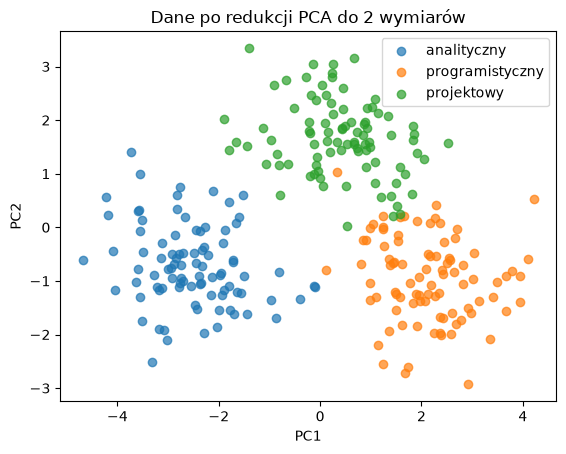

In [26]:
pca_2 = PCA(
    n_components=2
)

X_pca_2 = pca_2.fit_transform(
    X_scaled
)

pca_plot = pd.DataFrame({
    "PC1": X_pca_2[:, 0],
    "PC2": X_pca_2[:, 1],
    "profil": df["profil"]
})

for label in df["profil"].unique():
    temp = pca_plot[
        pca_plot["profil"] == label
    ]

    plt.scatter(
        temp["PC1"],
        temp["PC2"],
        label=label,
        alpha=0.7
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Dane po redukcji PCA do 2 wymiarów")
plt.legend()
plt.show()

## 9.1. Biplot – obserwacje i oryginalne zmienne na osiach PC1–PC2

Na zwykłym wykresie PCA widzimy położenie obserwacji w nowym układzie współrzędnych.

Biplot dodaje do tego **strzałki reprezentujące oryginalne zmienne**. Kierunek strzałki wynika z ładunków korelacyjnych zmiennej na PC1 i PC2.

Interpretacja:

- zmienne wskazujące w podobnym kierunku są zwykle dodatnio powiązane,
- zmienne skierowane przeciwnie są związane ujemnie,
- dłuższa strzałka oznacza silniejszy związek zmiennej z płaszczyzną PC1–PC2.

Długości strzałek są na wykresie przeskalowane tylko po to, aby były widoczne razem z punktami.


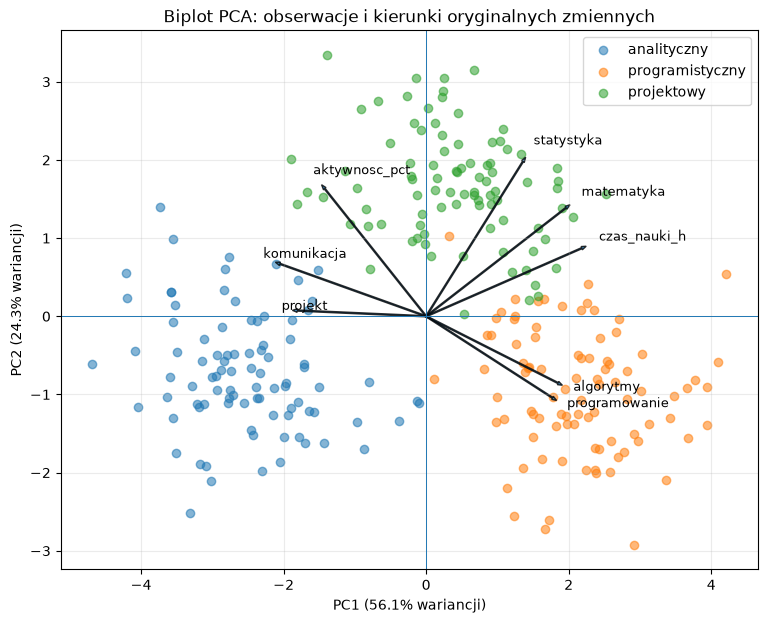

In [27]:
scores_2 = pd.DataFrame({
    "PC1": X_pca_2[:, 0],
    "PC2": X_pca_2[:, 1],
    "profil": df["profil"]
})

plt.figure(figsize=(9, 7))

for label in df["profil"].unique():
    temp = scores_2[scores_2["profil"] == label]
    plt.scatter(
        temp["PC1"],
        temp["PC2"],
        label=label,
        alpha=0.55
    )

arrow_scale = 0.75 * min(
    np.max(np.abs(X_pca_2[:, 0])),
    np.max(np.abs(X_pca_2[:, 1]))
)

for feature in features:
    x = correlation_loadings.loc[feature, "PC1"]
    y = correlation_loadings.loc[feature, "PC2"]

    plt.arrow(
        0, 0,
        x * arrow_scale,
        y * arrow_scale,
        width=0.015,
        length_includes_head=True,
        alpha=0.8
    )

    plt.text(
        x * arrow_scale * 1.08,
        y * arrow_scale * 1.08,
        feature,
        fontsize=9
    )

plt.axhline(0, linewidth=0.7)
plt.axvline(0, linewidth=0.7)
plt.xlabel(
    f"PC1 ({pca_2.explained_variance_ratio_[0]*100:.1f}% wariancji)"
)
plt.ylabel(
    f"PC2 ({pca_2.explained_variance_ratio_[1]*100:.1f}% wariancji)"
)
plt.title("Biplot PCA: obserwacje i kierunki oryginalnych zmiennych")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Co widać na biplocie?

Punkty pokazują obserwacje po transformacji do przestrzeni PC1–PC2.

Strzałki pomagają interpretować znaczenie osi:

- jeżeli kilka zmiennych ma strzałki skierowane podobnie, współtworzą podobny kierunek zmienności,
- obserwacje leżące w kierunku danej strzałki mają zwykle większe wartości odpowiadającej jej cechy,
- zmienne prawie prostopadłe są słabo skorelowane w tej dwuwymiarowej reprezentacji.

Biplot łączy więc dwa spojrzenia: **położenie obserwacji** oraz **związek oryginalnych cech z głównymi składowymi**.


# 10. Utrata informacji i odtworzenie danych

Jeżeli zachowamy mniej składowych, tracimy część informacji.

`inverse_transform()` pozwala w przybliżeniu odtworzyć dane w przestrzeni standaryzowanych cech.


In [28]:
pca_3 = PCA(
    n_components=3
)

X_pca_3 = pca_3.fit_transform(
    X_scaled
)

X_reconstructed_3 = pca_3.inverse_transform(
    X_pca_3
)

mse_3 = np.mean(
    (X_scaled - X_reconstructed_3)**2
)

print(
    "Błąd rekonstrukcji dla 3 składowych:",
    round(mse_3, 4)
)

Błąd rekonstrukcji dla 3 składowych: 0.0542


# 11. t-SNE

t-SNE jest metodą nieliniową używaną głównie do wizualizacji danych wysokowymiarowych.

W przeciwieństwie do PCA:

- osie t-SNE nie mają bezpośredniej interpretacji,
- metoda koncentruje się na zachowaniu lokalnych sąsiedztw,
- odległości między odległymi klastrami nie powinny być interpretowane jak w PCA,
- wynik zależy od parametrów i inicjalizacji.

Jednym z najważniejszych parametrów jest **perplexity**.


## 11.1. Wpływ parametru `perplexity`

Sprawdzimy trzy wartości:

- `5` – bardzo lokalne sąsiedztwo,
- `30` – wartość pośrednia,
- `60` – szersze sąsiedztwo.

Używamy tych samych standaryzowanych danych i tego samego `random_state`.


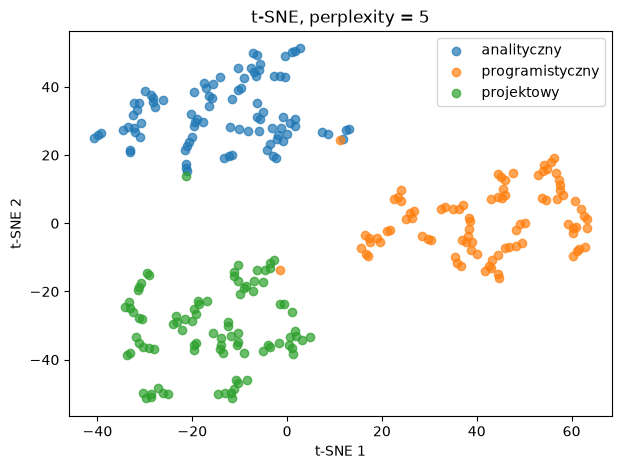

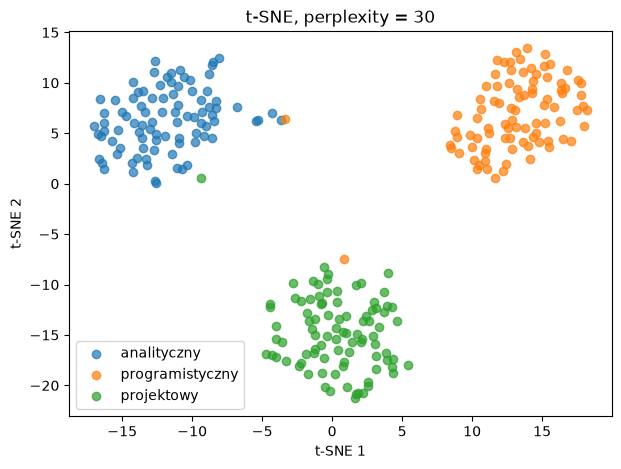

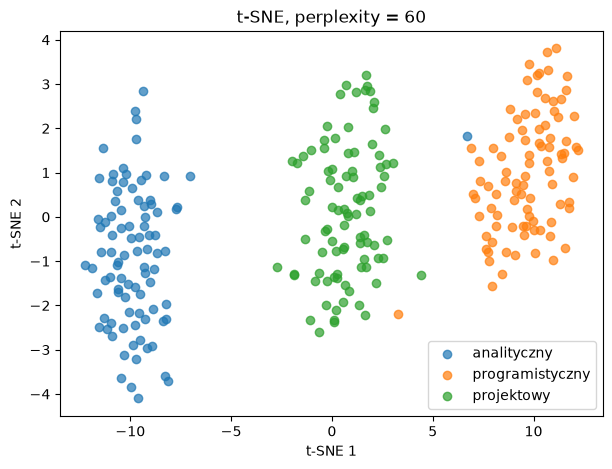

In [29]:
for perplexity in [5, 30, 60]:

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        learning_rate="auto",
        init="pca",
        max_iter=1000,
        random_state=42
    )

    X_tsne = tsne.fit_transform(
        X_scaled
    )

    tsne_df = pd.DataFrame({
        "TSNE1": X_tsne[:, 0],
        "TSNE2": X_tsne[:, 1],
        "profil": df["profil"]
    })

    plt.figure(figsize=(7, 5))

    for label in df["profil"].unique():
        temp = tsne_df[
            tsne_df["profil"] == label
        ]

        plt.scatter(
            temp["TSNE1"],
            temp["TSNE2"],
            label=label,
            alpha=0.7
        )

    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.title(
        f"t-SNE, perplexity = {perplexity}"
    )
    plt.legend()
    plt.show()

### Co obserwujemy?

Zmiana `perplexity` może zmienić:

- kształt grup,
- liczbę widocznych podgrup,
- odległości pomiędzy skupieniami.

Dlatego nie należy traktować pojedynczego wykresu t-SNE jako jedynego możliwego obrazu danych.

t-SNE służy przede wszystkim do badania **lokalnej struktury** i wizualizacji.


# 12. UMAP

UMAP również jest metodą nieliniową.

W typowym zastosowaniu:

- buduje strukturę sąsiedztwa,
- zachowuje lokalną strukturę danych,
- częściowo zachowuje również relacje bardziej globalne,
- może być używany do wizualizacji w 2D lub 3D.

Pakiet UMAP nie jest częścią podstawowego `scikit-learn`.  
Jeżeli nie jest zainstalowany, można go jednorazowo doinstalować:

```python
%pip install umap-learn
```

Po instalacji należy ponownie uruchomić kernel notebooka.


In [30]:
try:
    import umap.umap_ as umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print(
        "Brak pakietu umap-learn. "
        "Zainstaluj: %pip install umap-learn"
    )

Brak pakietu umap-learn. Zainstaluj: %pip install umap-learn


In [31]:
if UMAP_AVAILABLE:

    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=0.1
    )

    X_umap = reducer.fit_transform(
        X_scaled
    )

    umap_df = pd.DataFrame({
        "UMAP1": X_umap[:, 0],
        "UMAP2": X_umap[:, 1],
        "profil": df["profil"]
    })

    for label in df["profil"].unique():
        temp = umap_df[
            umap_df["profil"] == label
        ]

        plt.scatter(
            temp["UMAP1"],
            temp["UMAP2"],
            label=label,
            alpha=0.7
        )

    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.title("UMAP - redukcja do 2 wymiarów")
    plt.legend()
    plt.show()
else:
    print(
        "Sekcja UMAP zostanie wykonana po "
        "zainstalowaniu pakietu umap-learn."
    )

Sekcja UMAP zostanie wykonana po zainstalowaniu pakietu umap-learn.


# 13. PCA, t-SNE i UMAP – najważniejsze różnice

| Cecha | PCA | t-SNE | UMAP |
|---|---|---|---|
| Typ | liniowa | nieliniowa | nieliniowa |
| Główny cel | redukcja i analiza wariancji | wizualizacja | wizualizacja / redukcja |
| Struktura | głównie globalna | głównie lokalna | lokalna i częściowo globalna |
| Interpretacja osi | tak | nie | nie |

**Najważniejsze:** PCA jest metodą, którą można wykorzystać do utworzenia nowego zbioru o mniejszej liczbie zmiennych.  
t-SNE traktujemy przede wszystkim jako narzędzie do wizualizacji.


# 14. Zadania do samodzielnego wykonania

Zadania korzystają z tych samych danych, ale wymagają innych decyzji, innych parametrów lub interpretacji niż przykłady rozwiązane.


## Zadanie 1. PCA z innym progiem wariancji

Dla wszystkich 8 cech numerycznych:

1. wykonaj standaryzację,
2. zastosuj `PCA(n_components=0.85)`,
3. sprawdź, ile składowych zostało zachowanych,
4. oblicz sumę wyjaśnianej wariancji,
5. utwórz nową ramkę danych z kolumnami `PC1`, `PC2`, ... oraz `profil`.

Odpowiedz: **ile kolumn numerycznych zastąpiło 8 cech wejściowych?**


In [32]:
# TODO - Zadanie 1


## Zadanie 2. PCA bez standaryzacji i po standaryzacji

Wykonaj PCA dla cech:

- `matematyka`,
- `programowanie`,
- `czas_nauki_h`,
- `aktywnosc_pct`.

Porównaj dwa warianty:

1. PCA na danych surowych,
2. PCA po `StandardScaler`.

Porównaj `explained_variance_ratio_` i współczynniki PC1.

Wyjaśnij, dlaczego skala zmiennych może zmienić wynik PCA.


In [33]:
# TODO - Zadanie 2


## Zadanie 3. Interpretacja składowych na podstawie ładunków korelacyjnych

Skorzystaj z tabeli `correlation_loadings`.

1. Znajdź trzy cechy o największych wartościach bezwzględnych **ładunków korelacyjnych** dla PC1.
2. Znajdź trzy cechy o największych wartościach bezwzględnych ładunków dla PC2.
3. Spróbuj nadać obu składowym krótką interpretację.
4. Porównaj wynik z tabelą `eigenvector_coefficients`.

Odpowiedz:

**Czy współczynniki wektorów własnych i ładunki korelacyjne oznaczają dokładnie to samo?**

Pamiętaj:

- `eigenvector_coefficients` – składowe wektorów własnych, czyli współczynniki kierunków PCA,
- `correlation_loadings` – korelacje oryginalnych zmiennych z PC1, PC2, ...


In [34]:
# TODO - Zadanie 3


## Zadanie 4. Liczba składowych a utrata informacji

Wykonaj PCA dla:

- `n_components=2`,
- `n_components=4`.

Dla obu przypadków:

1. przekształć dane,
2. wykonaj `inverse_transform`,
3. policz średni błąd kwadratowy rekonstrukcji.

Który wariant lepiej odtwarza dane i dlaczego?


In [35]:
# TODO - Zadanie 4


## Zadanie 5. Inne wartości `perplexity`

Wykonaj t-SNE dla:

- `perplexity=10`,
- `perplexity=45`.

Użyj:

- `random_state=21`,
- `init="pca"`,
- `learning_rate="auto"`.

Narysuj dwa osobne wykresy i porównaj:

- zwartość grup,
- lokalne podgrupy,
- odległości między skupieniami.

Wyjaśnij, dlaczego nie należy interpretować globalnych odległości na wykresie t-SNE tak samo jak w PCA.


In [36]:
# TODO - Zadanie 5


## Zadanie 6. UMAP – wpływ wielkości sąsiedztwa

Jeżeli pakiet `umap-learn` jest dostępny, wykonaj UMAP dla:

- `n_neighbors=5`,
- `n_neighbors=40`.

Pozostaw:

- `n_components=2`,
- `min_dist=0.1`.

Porównaj wykresy.  
Która wartość mocniej podkreśla bardzo lokalną strukturę danych?


In [37]:
# TODO - Zadanie 6


## Zadanie 7. Porównanie metod

Porównaj trzy reprezentacje tych samych danych:

- PCA do 2 wymiarów,
- t-SNE (`perplexity=30`) do 2 wymiarów,
- UMAP do 2 wymiarów – jeżeli pakiet jest dostępny.

Odpowiedz:

1. która metoda ma osie możliwe do interpretacji,
2. która metoda najmocniej koncentruje się na lokalnym sąsiedztwie,
3. którą metodę wybrał(a)byś do utworzenia nowego zbioru z mniejszą liczbą cech do dalszego modelowania,
4. którą metodę wybrał(a)byś przede wszystkim do wizualizacji?


In [38]:
# TODO - Zadanie 7


# 15. Podsumowanie

Najważniejsze wnioski z zajęć:

- PCA tworzy **nowe cechy**, a nie wybiera kolumn ze zbioru wejściowego,
- `pca.components_` zawiera współczynniki kierunków (elementy wektorów własnych), a nie ładunki korelacyjne,
- ładunek korelacyjny to korelacja oryginalnej zmiennej z daną składową główną,
- biplot pozwala jednocześnie zobaczyć obserwacje w przestrzeni PC1–PC2 i kierunki związane z oryginalnymi zmiennymi,
- PC1 wyjaśnia największą możliwą część wariancji, kolejne składowe coraz mniej,
- liczba składowych może być mniejsza niż liczba oryginalnych cech,
- udział wariancji pomaga zdecydować, ile składowych zachować,
- PCA przez macierz kowariancji i PCA przez SVD są równoważne dla danych wycentrowanych, z możliwością odwrócenia znaków osi,
- `PCA(n_components=0.90)` może automatycznie wybrać liczbę składowych zachowujących co najmniej 90% wariancji,
- przy różnych skalach cech przed PCA zwykle wykonujemy standaryzację,
- t-SNE służy przede wszystkim do wizualizacji lokalnej struktury,
- `perplexity` wpływa na wielkość sąsiedztwa uwzględnianego przez t-SNE,
- UMAP również wykorzystuje sąsiedztwa, ale jego założenia i optymalizacja różnią się od t-SNE,
- dobry wykres 2D nie oznacza automatycznie, że reprezentacja jest najlepsza do modelowania predykcyjnego.


# Literatura i materiały

- **Charu C. Aggarwal**, *Data Mining: The Textbook*, Springer, 2015 – PCA, SVD i redukcja wymiarowości.
- **Steven S. Skiena**, *The Data Science Design Manual*, Springer, 2017 – PCA i SVD.
- **Laurens van der Maaten, Geoffrey Hinton**, *Visualizing Data using t-SNE*, Journal of Machine Learning Research, 2008.
- **Leland McInnes, John Healy, James Melville**, *UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction*, 2018.
- dokumentacja `scikit-learn` dla `PCA` i `TSNE`,
- dokumentacja `umap-learn` dla klasy `UMAP`.

Zbiór `redukcja_wymiarow_pracownia5.csv` został przygotowany wyłącznie do celów dydaktycznych.
